### O que esse código faz, no geral?

Ele treina um modelo de **classificação** para identificar três espécies de flores (íris) com base em medidas das pétalas e sépalas. Pense nisso como ensinar um sistema a reconhecer padrões — como um arquiteto que aprende a identificar estilos arquitetônicos olhando para características de uma planta baixa.

1. Importações:

In [199]:
from sklearn.datasets import load_iris
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split

Aqui você está "contratando ferramentas" da biblioteca `scikit-learn`. A `load_iris` traz um conjunto de dados clássico já pronto para uso. O `SVC` é o algoritmo de classificação (falaremos mais sobre ele). E o `train_test_split` é uma função que divide seus dados em dois grupos: um para treino e outro para teste.

2. Carregando os dados:

In [200]:
X, y = load_iris(return_X_y=True)

O dataset Iris contém 150 amostras de flores. `X` são as **features** (as medidas — comprimento e largura de pétalas e sépalas), e `y` são os **rótulos** (qual das três espécies cada flor pertence). Analogia: `X` é o "projeto arquitetônico" e `y` é o "estilo arquitetônico" que o projeto representa.

3. Dividindo em treino e teste:

In [201]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.50, random_state=42)

Com test_size=0.50, a divisão separa 50% dos dados para treino e 50% para teste: 75 amostras de Iris em cada conjunto. O random_state=42 fixa a aleatoriedade da divisão para os mesmos dados e ambiente.

O modelo é ajustado com X_train e y_train; as previsões avaliadas aqui usam X_test e y_test, que ficaram fora do ajuste. Métricas no treino podem ajudar a inspecionar o ajuste, mas não substituem a avaliação em dados separados.

4. Criando e treinando o modelo:

In [202]:
clf = SVC(kernel='linear', C=1.0)
clf.fit(X_train, y_train)

SVC(kernel='linear')

O `SVC` (Support Vector Classifier) é um algoritmo que busca traçar a melhor "fronteira de separação" possível entre as classes. O parâmetro `kernel='linear'` diz que essa fronteira será uma linha reta (ou, em múltiplas dimensões, um hiperplano). Já o `C=1.0` controla o compromisso entre uma margem mais ampla e a penalização das violações dessa margem no treino. Valores menores de `C` aumentam a regularização e toleram mais violações; isso pode ajudar a generalização ou causar subajuste. A escolha de `C` deve ser avaliada em validação, sem garantir melhora na acurácia de dados novos. O `.fit()` é o momento do aprendizado: o modelo "estuda" os dados de treino.

5. Fazendo previsões

In [203]:
y_pred = clf.predict(X_test)

O método `.predict()` recebe as features (`X_test`). O resultado é armazenado na variável `y_pred`.

### Como ver os resultados?

Aqui estão as formas mais úteis de avaliar o desempenho do seu modelo:

Acurácia: 1.0

Relatório de Classificação:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        29
           1       1.00      1.00      1.00        23
           2       1.00      1.00      1.00        23

    accuracy                           1.00        75
   macro avg       1.00      1.00      1.00        75
weighted avg       1.00      1.00      1.00        75



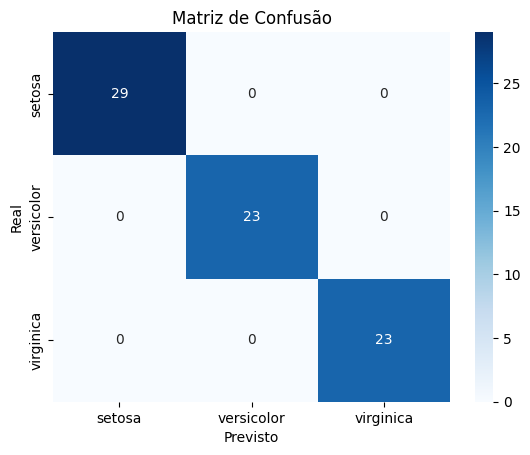

In [204]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Fazendo as previsões
y_pred = clf.predict(X_test)

# 1. Acurácia: porcentagem de acertos geral
print("Acurácia:", accuracy_score(y_test, y_pred))

# 2. Relatório completo: precisão, recall e f1-score por classe
print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred))

# 3. Matriz de confusão — mostra onde o modelo errou
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["setosa", "versicolor", "virginica"],
            yticklabels=["setosa", "versicolor", "virginica"])
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.title("Matriz de Confusão")
plt.show()

A **acurácia** te diz de forma direta "o modelo acertou X% das flores". O **relatório de classificação** vai mais fundo, mostrando o desempenho por espécie. E a **matriz de confusão** é como um mapa de erros — ela te mostra, por exemplo, se o modelo confundiu a espécie A com a espécie B com frequência.